# Distilling Expert Knownldge using LLM

Why selecting ches? Chess is very hard, Lichess chess database has trillions of positions & Stockfish is close to an oracle
So, no way you can memorize the moves, but you need to learn strategy, that is not simple.
This project uses the concept of on-policy distillation, to distill the expert knowldge into an LLM model.

The notebook walks through the training math used in this repo — **no training is run**. One fixed chess
position is used throughout, and every concept is shown on a small worked example with the
intermediate values printed, so each number can be checked by hand.

| § | Topic |
|---|-------|
| 0 | Setup: Qwen3-1.7B (CPU, bfloat16), python-chess, Stockfish, the fixed FEN |
| 1 | Where this fits: SFT vs RL/GRPO vs on-policy distillation |
| 2 | GRPO loss on hand-set toy tensors (ratio, clip, KL, aggregation) + hand verification |
| 3 | GRPO on a real sampled group from Qwen3-1.7B, scored by Stockfish |
| 4 | On-policy distillation: per-token reverse KL over a student trace |
| 5 | Side-by-side: how dense is each training signal? |
| 6 | Takeaways |

**Runtime:** a few minutes on a CPU-only laptop. **First run downloads `Qwen/Qwen3-1.7B` (~3.4 GB)**
from the Hugging Face Hub into the local HF cache; later runs are offline-fast. Same default base model as the rest of this repo (`scripts/train_sft.sh`, `SFTConfig.model_name`).

**Environment:** CPU-only torch — see the install line in the repo's `notebooks/README.md`
(`uv venv` + `uv pip install torch --index-url https://download.pytorch.org/whl/cpu transformers ...`).

## Refrences
1. [Rethinking On-Policy Distillation of Large Language
Models II: One Training Example](https://arxiv.org/pdf/2609.04172)
2. [DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models](https://arxiv.org/pdf/2402.03300)
3. [Learning to Reason under Off-Policy Guidance](https://arxiv.org/abs/2504.14945)

## 0. Setup

Imports and global constants. Everything is seeded so the notebook is reproducible run-to-run
(CPU sampling with a fixed `torch.manual_seed` is deterministic). Figures are written to
`notebooks/figures/` **and** shown inline.

In [2]:
import math
import os
import re
import statistics
from pathlib import Path

import chess
import chess.engine
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer

SEED = 0
torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# One position for the whole notebook: Italian Game, White to move.
FEN = "r1bqk2r/pppp1ppp/2n2n2/2b1p3/2B1P3/2NP1N2/PPP2PPP/R1BQK2R w KQkq - 4 5"
board = chess.Board(FEN)
print(board)
print()
print("Side to move:", "White" if board.turn else "Black", "| legal moves:", board.legal_moves.count())

r . b q k . . r
p p p p . p p p
. . n . . n . .
. . b . p . . .
. . B . P . . .
. . N P . N . .
P P P . . P P P
R . B Q K . . R

Side to move: White | legal moves: 40


### Stockfish

Stockfish is the reward model / judge. The binary lives **outside** the repo at `~/.local/bin/stockfish`.
We use one persistent engine with `Threads=1` and a fixed depth so evaluations are deterministic.

The reward is the repo's actual design (`qwen_chess_rl/training/rl/reward.py`, `docs/rewards.md`):

$$r = Q(s,a) = P(\text{mover wins} \mid \text{position after the move}) \in [0,1], \qquad p = \frac{1}{1 + 10^{-cp/400}}$$

Stockfish scores the position *after* the move from the **opponent's** perspective (they are now to move),
so the mover's reward is `1 − winprob_after`. Mate ⇒ 1.0, illegal / unparseable move ⇒ −1.0 floor.

In [3]:
STOCKFISH_PATH = os.path.expanduser("~/.local/bin/stockfish")
if not (os.path.isfile(STOCKFISH_PATH) and os.access(STOCKFISH_PATH, os.X_OK)):
    raise FileNotFoundError(
        f"Stockfish not found/executable at {STOCKFISH_PATH}. Install Stockfish 17+ "
        "(e.g. download from https://stockfishchess.org/download/) and place the binary there."
    )

EVAL_DEPTH = 12          # repo default (docs/rewards.md)
CP_SCALE = 400.0         # Lichess-scale logistic
ILLEGAL_REWARD = -1.0    # hard floor for illegal / unparseable moves

engine = chess.engine.SimpleEngine.popen_uci(STOCKFISH_PATH)
engine.configure({"Threads": 1, "Hash": 16})
print(engine.id["name"])


def score_to_win_prob(score: chess.engine.Score) -> float:
    # Win probability for the side to move (mirrors reward.py::_score_to_win_prob).
    if score.is_mate():
        return 1.0 if score.mate() > 0 else 0.0
    return 1.0 / (1.0 + 10.0 ** (-score.score() / CP_SCALE))


def move_reward(fen: str, uci: str | None) -> dict:
    # r = 1 - winprob_after (mover's perspective); -1.0 if illegal.
    b = chess.Board(fen)
    try:
        move = chess.Move.from_uci(uci) if uci else None
    except ValueError:
        move = None
    if move is None or move not in b.legal_moves:
        return {"move": uci, "san": "illegal", "legal": False, "cp_after": None, "reward": ILLEGAL_REWARD}
    san = b.san(move)
    b.push(move)
    info = engine.analyse(b, chess.engine.Limit(depth=EVAL_DEPTH))
    score = info["score"].relative          # relative to the opponent (now to move)
    reward = 1.0 - score_to_win_prob(score)
    cp_mover = -score.score(mate_score=100_000)
    return {"move": uci, "san": san, "legal": True, "cp_after": cp_mover, "reward": reward}


root_info = engine.analyse(board, chess.engine.Limit(depth=EVAL_DEPTH))
BEST_UCI = root_info["pv"][0].uci()
BEST_SAN = board.san(root_info["pv"][0])
ROOT_CP = root_info["score"].relative.score(mate_score=100_000)
print(f"Stockfish (depth {EVAL_DEPTH}) best move: {BEST_SAN} ({BEST_UCI}), eval {ROOT_CP:+d} cp for White")

Stockfish 16
Stockfish (depth 12) best move: Nd5 (c3d5), eval +44 cp for White


### Load Qwen3-1.7B (CPU, bfloat16)

The same base model the repo trains by default (`Qwen/Qwen3-1.7B`, see `SFTConfig.model_name` /
`docs/training.md`). Loaded on CPU in bfloat16 — no CUDA, no vLLM. `eval()` mode; we never call
`.backward()` in this notebook.

> **First run note:** this downloads ~3.4 GB of weights into `~/.cache/huggingface`.

In [4]:
MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.bfloat16)
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_ID}: {n_params:,} parameters ({n_params / 1e6:.0f}M), dtype={next(model.parameters()).dtype}")
_eos = model.generation_config.eos_token_id
EOS_IDS = set(_eos if isinstance(_eos, list) else [_eos])
print("EOS ids:", sorted(EOS_IDS), "| pad id:", tokenizer.pad_token_id)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Qwen/Qwen3-1.7B: 1,720,574,976 parameters (1721M), dtype=torch.bfloat16
EOS ids: [151643, 151645] | pad id: 151643


## 1. Where this fits: SFT vs RL (GRPO) vs on-policy distillation

Three ways to turn expert judgment into model weights. The two axes that matter are
**who generates the tokens we train on** (off-policy vs on-policy) and **how much feedback each token gets**
(sparse vs dense).

| | Tokens trained on are sampled by | Feedback signal | Density | Main failure mode |
|---|---|---|---|---|
| **SFT** (supervised fine-tuning) | the teacher / dataset (**off-policy**) | cross-entropy on every target token | **dense** | exposure bias — the student never visits its own states during training |
| **RL / GRPO** | the student (**on-policy**) | one scalar reward per completion (here: Stockfish $Q(s,a)$), turned into a group-relative advantage | **sparse** | credit assignment: every token of a completion gets the same advantage |
| **On-policy distillation (OPD)** | the student (**on-policy**) | teacher log-probs on the *student's own prefix*, per token | **dense** | thinking-pattern mismatch / teacher has no new knowledge |

From the OPD notes (*"How to Learn On-Policy Distillation"*):

```
Traditional KD (off-policy):
  Teacher generates response → Student trains on fixed teacher tokens
  Problem: Student never visits its own states during training → exposure bias

OPD (on-policy):
  Student generates its own response → Teacher provides per-token feedback
  Advantage: Dense token-level reward signal on states the student actually visits
```

The OPD pipeline (student samples → teacher scores the **same** prefixes → per-token KL):

```text
Prompt x
   │
   ▼
Student πθ samples ŷ ──────────────────────────────┐
   │                                               │
   ▼                                               │
Student prefix ŷ<t ──► Teacher πT (same prefix)    │
   │                         │                     │
   ▼                         ▼                     │
pt (student)              qt (teacher)             │
   │                         │                     │
   └──────────► KL per token ◄─┘                   │
                   │                               │
                   ▼                               │
         Loss = Σ_t KL(pt ∥ qt)                    │
                   │                               │
                   ▼                               │
            Update θ ──────────────────────────────┘
```


OPD is "on-policy like RL, dense like SFT". §2–3 build the GRPO loss; §4 builds the OPD loss;
§5 puts the three signals next to each other on the same position.

## Why prompt will not work?

Lichess hands us **trillions of positions** and Stockfish is **close to an oracle** — so the raw signal exists. The difficulty is everything around it (Adithya Bhaskar's thread on the Queen paper, arXiv:2610.03695, makes the same points from a much bigger project):

1. **The data is not in the right format to learn explanations.** Engines emit centipawn evaluations and principal variations — not natural-language reasoning. There is no corpus of position → expert *explanation*; you have to manufacture one (Queen seeds theirs from a frontier model, then improves it).
2. **Even legality is hard for pretrained LMs.** Before GPT-5.6-Sol, no language model except Gemini could play legal moves consistently — the action space (~35 moves/ply, strict syntax) is adversarial to next-token prediction. Our own eval hits the same wall: legal-move rate is the *floor*, not the achievement.
3. **Explanations need search; LMs have none.** A good explanation states the best move, the predicted principal variation, *and why the alternatives are worse*. That is look-ahead — an LM's weights do not do it natively, it has to be distilled in (Queen's natural-language Bellman update; our GRPO + distillation stages).
4. **Playing strength is a prerequisite.** An explanation of a weak move is a confident wrong answer. This is why headline playing strength barely moved for us while behaviour changed — and why Queen needed 7 iterations (+915 Elo) before its prose was worth trusting.
5. **The expert's knowledge is latent, not verbal.** Stockfish (or a chess encoder) 'knows' the position but cannot speak; the LM can speak but does not know. Coupling the two is an architecture problem (cross-attention to a silent encoder in Queen) — a different failure surface than pure training.

So the recipe anyone converges on — labelled expert signal, group-relative RL from that signal, then distillation back into the policy — is not a fashion choice. It is the workaround for the five walls above. Sources: [arXiv:2610.03695](https://arxiv.org/abs/2610.03695) (Queen, Princeton PLI), [the thread](https://x.com/AdithyaNLP/status/2107123927525077505).


## 2. GRPO loss: toy-tensor version
![grpo loss](figures/grpo-loss.png)
GRPO in four pieces (from the GRPO-loss notes):

1. **Ratio** of token probabilities between the policy being updated and the policy that sampled
2. **Advantages** — group-relative, so no critic is needed
3. **Clipping** — so a single update can't move the ratio too far
4. **KL divergence** to a frozen reference model
Here $\pi_{ref}$ is the reference policy distribution and $\pi_\theta$ is the student policy


We use **G = 4** candidate moves for our position. Rewards are **real** (Stockfish); the per-token
log-probs are **hand-set tensors** so every number below can be recomputed by hand.

### Kullback–Leibler divergence
Alright, now let’s say we want to infer $p(z|X)$ using $q(z|X)$. The KL divergence then formulated as follows:
$$
D_{KL}[q[z|X)||p(z|X)] = \sum_z q(z|X) \log \frac{q(z|X)}{p(z|X)} = E_q[\log q(z|X) - \log p(z|X)]$$
### What KL-Divergence do?
* allows use to compare 2 probability distributions
* if $q$ is the same as  $p$, then KLD = 0
* if $q$ is different from  $p$, KLD > 0




### 2.1 Rewards from Stockfish

Four candidate moves for White: castling, the pin Bg5, a quiet pawn move, and the speculative
Bxf7+ sacrifice. Each gets the repo reward $r = 1 - \text{winprob}_{\text{after}}$ (§0).

![scoring 4](figures/scoring-four-chess-moves.gif)

In [5]:
TOY_MOVES = ["e1g1", "c1g5", "a2a3", "c4f7"]
toy_scored = [move_reward(FEN, m) for m in TOY_MOVES]
toy_rewards = torch.tensor([s["reward"] for s in toy_scored], dtype=torch.float64)
print(pd.DataFrame(toy_scored)[["move", "san", "cp_after", "reward"]].round(4).to_string(index=False))

move   san  cp_after  reward
e1g1   O-O        34  0.5488
c1g5   Bg5        38  0.5545
a2a3    a3        50  0.5715
c4f7 Bxf7+      -276  0.1696


Reading the rewards: the three quiet moves land within a few tens of centipawns of each other. At depth 12
that is inside engine noise, so don't over-read their order (it can even disagree with Stockfish's root
best move printed in §0). The sacrifice is the real outlier, and the advantages below are driven by it.

### 2.2 Group-relative advantage

GRPO replaces PPO's learned critic with the group statistics of the $G$ completions sampled for the
same prompt:

$$A_i = \frac{r_i - \operatorname{mean}(r)}{\operatorname{std}(r)}$$

We use the sample standard deviation (Bessel-corrected, `torch.std` default — what TRL does) and add a
tiny $\epsilon_{\text{std}} = 10^{-4}$ to the denominator. That handles the degenerate **std = 0** case: if all $G$
rewards are equal (e.g. all four moves illegal ⇒ all −1.0), every advantage is exactly 0 and the group
contributes **no policy gradient** — there is nothing to prefer.

In [6]:
STD_EPS = 1e-4


def group_advantages(rewards: torch.Tensor, eps: float = STD_EPS) -> torch.Tensor:
    # A_i = (r_i - mean(r)) / std(r); std = 0 -> all-zero advantages (via eps).
    if rewards.numel() < 2:
        return torch.zeros_like(rewards)
    return (rewards - rewards.mean()) / (rewards.std() + eps)


toy_adv = group_advantages(toy_rewards)
print("rewards   :", [round(x, 4) for x in toy_rewards.tolist()])
print(f"mean={toy_rewards.mean():.4f}  std={toy_rewards.std():.4f}")
print("advantages:", [round(x, 4) for x in toy_adv.tolist()])
print("sum of advantages (≈0 by construction):", round(toy_adv.sum().item(), 10))

# Degenerate group: every reward equal -> std = 0 -> zero advantages, no NaN.
print("std=0 case:", group_advantages(torch.tensor([-1.0, -1.0, -1.0, -1.0], dtype=torch.float64)).tolist())

rewards   : [0.5488, 0.5545, 0.5715, 0.1696]
mean=0.4611  std=0.1946
advantages: [0.4505, 0.4798, 0.5671, -1.4974]
sum of advantages (≈0 by construction): 0.0
std=0 case: [0.0, 0.0, 0.0, 0.0]


### 2.3 Hand-set per-token log-probabilities

Pretend each move was emitted as a short completion (move + a few words of justification) of a
different length: 2, 3, 4 and 6 tokens. Shorter completions are right-padded; `mask` marks real tokens.

- `logp_old` — $\log \pi_{\text{old}}$: log-probs under the policy that **sampled** the completions
- `logp_new` — $\log \pi_\theta$: log-probs under the policy **being updated** (after some steps)
- `logp_ref` — $\log \pi_{\text{ref}}$: log-probs under the frozen **reference** model

Values are chosen so that some tokens fall outside the clip window $[1-\varepsilon, 1+\varepsilon]$ in
**both** directions, whatever the sign of each advantage.

In [7]:
TOY_LENGTHS = [2, 3, 4, 6]
L_MAX = max(TOY_LENGTHS)


def pad_rows(rows, fill=0.0):
    return torch.tensor([r + [fill] * (L_MAX - len(r)) for r in rows], dtype=torch.float64)


logp_old = pad_rows([
    [-0.50, -1.20],
    [-0.80, -0.20, -2.00],
    [-1.00, -0.40, -0.60, -1.50],
    [-0.30, -0.90, -1.10, -0.20, -0.70, -2.50],
])
logp_new = pad_rows([
    [-0.30, -1.50],
    [-0.75, -0.10, -2.40],
    [-0.70, -0.45, -0.60, -1.60],
    [-0.35, -0.60, -1.40, -0.20, -0.65, -2.00],
])
logp_ref = pad_rows([
    [-0.60, -1.20],
    [-0.80, -0.30, -1.90],
    [-1.10, -0.40, -0.50, -1.50],
    [-0.30, -1.00, -1.10, -0.30, -0.70, -2.20],
])
mask = pad_rows([[1.0] * n for n in TOY_LENGTHS])
print("mask:\n", mask.int())

mask:
 tensor([[1, 1, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1]], dtype=torch.int32)


### 2.4 Ratio, PPO clip, KL penalty — per token

Following the notes' `grpo_loss_with_kl` exactly:

$$\text{ratio} = \frac{\pi_\theta}{\pi_{\text{old}}} = \exp(\log \pi_\theta - \log \pi_{\text{old}})$$

$$\text{unclipped} = \text{ratio}\cdot A, \qquad \text{clipped} = \operatorname{clamp}(\text{ratio},\, 1-\varepsilon,\, 1+\varepsilon)\cdot A, \qquad \text{policy\_loss} = \min(\text{unclipped}, \text{clipped})$$

$$\Delta = \log \pi_\theta - \log \pi_{\text{ref}}, \qquad \text{per\_token\_kl} = e^{-\Delta} + \Delta - 1 \quad \big(= KL(\pi_{\text{ref}} \,\|\, \pi)\ \text{estimator}\big)$$

$$\text{per\_token\_loss} = -(\text{policy\_loss} - \beta \cdot \text{per\_token\_kl})$$

with $\varepsilon = 0.2$, $\beta = 0.1$. The minus sign is because optimisers *minimise* and we want to
*maximise* advantage-weighted probability.

*Notation note:* the notes' single-step LoRA lesson writes the ratio as `p_model / p_ref` because there the
sampling policy **is** the reference. In general (multiple updates per batch) the denominator is
$\pi_{\text{old}}$, the policy that sampled, and $\pi_{\text{ref}}$ only appears in the KL term.

**When is the KL term dropped?** Setting $\beta = 0$ removes it. DAPO and most recent reasoning-RL recipes
do this: with verifiable rewards (like a Stockfish eval) the policy is *supposed* to move far from the
initial model, the clip already bounds each step, and dropping $\pi_{\text{ref}}$ saves one full forward pass
per batch. Keep $\beta > 0$ when the reward is hackable or you need to stay close to the base model's style.

In [8]:
EPS_CLIP = 0.2
BETA = 0.1


def grpo_token_terms(logp_new, logp_old, logp_ref, adv, eps=EPS_CLIP, beta=BETA):
    # Per-token GRPO quantities; adv has shape (G,) and is broadcast over tokens.
    A = adv[:, None]
    ratio = torch.exp(logp_new - logp_old)
    unclipped = ratio * A
    clipped = torch.clamp(ratio, 1 - eps, 1 + eps) * A
    policy_loss = torch.min(unclipped, clipped)
    delta = logp_new - logp_ref
    per_token_kl = torch.exp(-delta) + delta - 1
    per_token_loss = -(policy_loss - beta * per_token_kl)
    return {
        "ratio": ratio,
        "clipped_term": clipped,
        "policy_loss": policy_loss,
        "per_token_kl": per_token_kl,
        "per_token_loss": per_token_loss,
        # min() picked the clipped branch and it differs -> no gradient through ratio for this token
        "was_clipped": (clipped < unclipped),
    }


toy = grpo_token_terms(logp_new, logp_old, logp_ref, toy_adv)
for name in ["ratio", "policy_loss", "per_token_kl", "per_token_loss"]:
    print(f"{name}:\n{(toy[name] * mask).numpy().round(4)}\n")
print("tokens where the clipped branch is active (gradient = 0):\n", (toy["was_clipped"] & mask.bool()).int())

ratio:
[[1.2214 0.7408 0.     0.     0.     0.    ]
 [1.0513 1.1052 0.6703 0.     0.     0.    ]
 [1.3499 0.9512 1.     0.9048 0.     0.    ]
 [0.9512 1.3499 0.7408 1.     1.0513 1.6487]]

policy_loss:
[[ 0.5406  0.3338  0.      0.      0.      0.    ]
 [ 0.5044  0.5302  0.3216  0.      0.      0.    ]
 [ 0.6805  0.5394  0.5671  0.5131  0.      0.    ]
 [-1.4244 -2.0213 -1.1979 -1.4974 -1.5742 -2.4688]]

per_token_kl:
[[0.0408 0.0499 0.     0.     0.     0.    ]
 [0.0012 0.0187 0.1487 0.     0.     0.    ]
 [0.0703 0.0013 0.0052 0.0052 0.     0.    ]
 [0.0013 0.0703 0.0499 0.0048 0.0012 0.0187]]

per_token_loss:
[[-0.5366 -0.3288 -0.     -0.     -0.     -0.    ]
 [-0.5043 -0.5284 -0.3067 -0.     -0.     -0.    ]
 [-0.6735 -0.5393 -0.5666 -0.5126 -0.     -0.    ]
 [ 1.4245  2.0283  1.2029  1.4979  1.5743  2.4707]]

tokens where the clipped branch is active (gradient = 0):
 tensor([[1, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0],
        [0, 0, 1, 0, 0, 0]], dt

### 2.5 Aggregating tokens into one loss — sequence-mean vs token-mean

The notes' loss for one completion is the masked token mean:
`loss = (per_token_loss * completion_mask).sum() / completion_mask.sum()`.
How you combine **several** completions is where GRPO variants differ:

| Variant | Aggregation | Weight of one token in completion $i$ |
|---|---|---|
| **GRPO** (sequence-mean) | $\frac{1}{G}\sum_i \frac{1}{\lvert o_i\rvert}\sum_t \ell_{i,t}$ | $\frac{1}{G\,\lvert o_i\rvert}$ |
| **DAPO** (token-mean) | $\frac{1}{\sum_i \lvert o_i\rvert}\sum_i\sum_t \ell_{i,t}$ | $\frac{1}{\sum_j \lvert o_j\rvert}$ |
| **Dr. GRPO** (constant) | $\frac{1}{G\cdot L_{\max}}\sum_i\sum_t \ell_{i,t}$ | $\frac{1}{G\,L_{\max}}$ |

($\ell_{i,t}$ here is `per_token_loss` of token $t$ in completion $i$.)

**Length bias:** under sequence-mean, a token in a long completion gets a *smaller* weight. For a
*negative* advantage this means long wrong answers are punished less per token than short wrong ones —
the policy learns that rambling dilutes the penalty. Token-mean and Dr. GRPO weight all tokens equally.

In [8]:
def aggregate(per_token_loss, mask, how):
    if how == "grpo_seq_mean":
        return ((per_token_loss * mask).sum(1) / mask.sum(1)).mean()
    if how == "dapo_token_mean":
        return (per_token_loss * mask).sum() / mask.sum()
    if how == "dr_grpo":
        return (per_token_loss * mask).sum() / (mask.shape[0] * mask.shape[1])
    raise ValueError(how)


for how in ["grpo_seq_mean", "dapo_token_mean", "dr_grpo"]:
    print(f"{how:16s} loss = {aggregate(toy['per_token_loss'], mask, how).item():+.6f}")

# Length-bias demo: a short (2-token) and a long (8-token) completion, both A = -1, ratio = 1, beta = 0.
demo_lens = [2, 8]
demo_mask = torch.tensor([[1.0] * 2 + [0.0] * 6, [1.0] * 8], dtype=torch.float64)
demo_terms = grpo_token_terms(torch.zeros_like(demo_mask), torch.zeros_like(demo_mask), torch.zeros_like(demo_mask),
                              torch.tensor([-1.0, -1.0], dtype=torch.float64), beta=0.0)
demo_loss = demo_terms["per_token_loss"]          # = -(1 * -1) = +1 on every real token
G_demo, n_tok, L_demo = 2, demo_mask.sum().item(), demo_mask.shape[1]
print("\nShort (2 tok) vs long (8 tok) completion, both A = -1 (per_token_loss = +1 on each token):")
print(pd.DataFrame({
    "n_tokens": demo_lens,
    "GRPO per-token weight": [1 / (G_demo * n) for n in demo_lens],
    "DAPO per-token weight": [1 / n_tok] * 2,
    "Dr.GRPO per-token weight": [1 / (G_demo * L_demo)] * 2,
    "GRPO penalty on seq": [(demo_loss[i] * demo_mask[i]).sum().item() / (G_demo * demo_lens[i]) for i in range(2)],
    "DAPO penalty on seq": [(demo_loss[i] * demo_mask[i]).sum().item() / n_tok for i in range(2)],
}).round(4).to_string(index=False))

grpo_seq_mean    loss = +0.061135
dapo_token_mean  loss = +0.383998
dr_grpo          loss = +0.239999

Short (2 tok) vs long (8 tok) completion, both A = -1 (per_token_loss = +1 on each token):
 n_tokens  GRPO per-token weight  DAPO per-token weight  Dr.GRPO per-token weight  GRPO penalty on seq  DAPO penalty on seq
        2                 0.2500                    0.1                    0.0625                  0.5                  0.2
        8                 0.0625                    0.1                    0.0625                  0.5                  0.8


### 2.6 The table

One row per sampled move. `ratio` and `clipped term` are token means over the completion;
`loss contribution` is the row's share of the GRPO sequence-mean loss,
$\frac{1}{G}\cdot\frac{1}{\lvert o_i\rvert}\sum_t \text{per\_token\_loss}_{i,t}$, so the column sums to the total loss.

In [9]:
def grpo_table(moves, rewards, adv, terms, mask):
    n = mask.sum(1)
    G_ = mask.shape[0]

    def tmean(x):
        return (x * mask).sum(1) / n

    return pd.DataFrame({
        "move": moves,
        "n_tokens": n.int().tolist(),
        "reward": rewards.tolist(),
        "advantage": adv.tolist(),
        "ratio (mean)": tmean(terms["ratio"]).tolist(),
        "clipped term (mean)": tmean(terms["clipped_term"]).tolist(),
        "n_clipped": (terms["was_clipped"] & mask.bool()).sum(1).tolist(),
        "KL (mean)": tmean(terms["per_token_kl"]).tolist(),
        "loss contribution": (tmean(terms["per_token_loss"]) / G_).tolist(),
    })


toy_table = grpo_table(TOY_MOVES, toy_rewards, toy_adv, toy, mask)
print(toy_table.round(4).to_string(index=False))
print(f"\nsum of contributions = {toy_table['loss contribution'].sum():+.6f}"
      f"  | GRPO seq-mean loss = {aggregate(toy['per_token_loss'], mask, 'grpo_seq_mean').item():+.6f}")

move  n_tokens  reward  advantage  ratio (mean)  clipped term (mean)  n_clipped  KL (mean)  loss contribution
e1g1         2  0.5316     0.5333        0.9811               0.5333          1     0.0453            -0.1283
c1g5         3  0.5043     0.3906        0.9423               0.3849          0     0.0562            -0.0906
a2a3         4  0.5388     0.5708        1.0515               0.5788          1     0.0205            -0.1442
c4f7         6  0.1437    -1.4947        1.1236              -1.5451          1     0.0244             0.4242

sum of contributions = +0.061135  | GRPO seq-mean loss = +0.061135


### 2.7 Hand verification

Recompute one row (the longest completion, `c4f7`, 6 tokens — it contains clipped tokens) with plain
Python floats and `math`, no torch, and **assert** it matches the tensor version. Also re-check the notes'
sanity claim: *at step 1 the policy equals the reference, so ratio = 1, KL = 0 and the loss is just −A*.

In [10]:
i = 3
r = [float(x) for x in toy_rewards]
mean_r = sum(r) / len(r)
std_r = statistics.stdev(r)                       # sample std, same as torch.std
A_i = (r[i] - mean_r) / (std_r + STD_EPS)

n_i = TOY_LENGTHS[i]
old_i, new_i, ref_i = (t[i, :n_i].tolist() for t in (logp_old, logp_new, logp_ref))
tok_loss, tok_ratio, tok_clip = [], [], []
for lo, ln, lr in zip(old_i, new_i, ref_i):
    ratio = math.exp(ln - lo)
    unclipped = ratio * A_i
    clipped = min(max(ratio, 1 - EPS_CLIP), 1 + EPS_CLIP) * A_i
    pol = min(unclipped, clipped)
    d = ln - lr
    kl = math.exp(-d) + d - 1
    tok_loss.append(-(pol - BETA * kl))
    tok_ratio.append(ratio)
    tok_clip.append(clipped)
    print(f"  ratio={ratio:.6f} clamp={min(max(ratio, 0.8), 1.2):.4f} A={A_i:+.6f} "
          f"policy={pol:+.6f} Δ={d:+.2f} kl={kl:.6f} token_loss={tok_loss[-1]:+.6f}")

hand = {
    "advantage": A_i,
    "ratio (mean)": sum(tok_ratio) / n_i,
    "clipped term (mean)": sum(tok_clip) / n_i,
    "loss contribution": sum(tok_loss) / n_i / len(r),
}
for k, v in hand.items():
    t = toy_table.loc[i, k]
    print(f"{k:22s} hand={v:+.10f}  tensor={t:+.10f}")
    assert abs(v - t) < 1e-9, (k, v, t)

# Notes' sanity check: pi_theta = pi_old = pi_ref  ->  ratio 1, KL 0, loss = -A.
same = grpo_token_terms(logp_old, logp_old, logp_old, toy_adv)
seq_loss = (same["per_token_loss"] * mask).sum(1) / mask.sum(1)
assert torch.allclose(seq_loss, -toy_adv), (seq_loss, toy_adv)
print("\n✓ hand-computed row matches the tensor implementation")
print("✓ with pi_theta == pi_old == pi_ref, per-sequence loss == -A:", seq_loss.numpy().round(4))

  ratio=0.951229 clamp=0.9512 A=-1.494686 policy=-1.421790 Δ=-0.05 kl=0.001271 token_loss=+1.421917
  ratio=1.349859 clamp=1.2000 A=-1.494686 policy=-2.017615 Δ=+0.40 kl=0.070320 token_loss=+2.024647
  ratio=0.740818 clamp=0.8000 A=-1.494686 policy=-1.195749 Δ=-0.30 kl=0.049859 token_loss=+1.200735
  ratio=1.000000 clamp=1.0000 A=-1.494686 policy=-1.494686 Δ=+0.10 kl=0.004837 token_loss=+1.495170
  ratio=1.051271 clamp=1.0513 A=-1.494686 policy=-1.571320 Δ=+0.05 kl=0.001229 token_loss=+1.571443
  ratio=1.648721 clamp=1.2000 A=-1.494686 policy=-2.464321 Δ=+0.20 kl=0.018731 token_loss=+2.466194
advantage              hand=-1.4946862136  tensor=-1.4946862136
ratio (mean)           hand=+1.1236498033  tensor=+1.1236498033
clipped term (mean)    hand=-1.5451320031  tensor=-1.5451320031
loss contribution      hand=+0.4241710902  tensor=+0.4241710902

✓ hand-computed row matches the tensor implementation
✓ with pi_theta == pi_old == pi_ref, per-sequence loss == -A: [-0.5333 -0.3906 -0.5708  1

### 2.8 The KL penalty as a "gravitational pull" toward the reference

Plot of $e^{-\Delta} + \Delta - 1$ against $\Delta = \log\pi - \log\pi_{\text{ref}}$ (as in the notes). It is
0 at $\Delta = 0$, always non-negative, and asymmetric: it grows linearly for over-confidence
($\Delta > 0$) and exponentially when the policy drops a token the reference likes ($\Delta < 0$).
The dots are the actual per-token KL values from the toy batch.

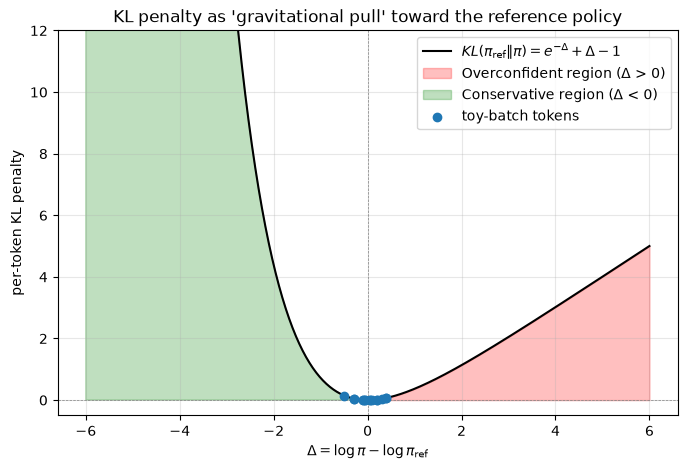

In [11]:
delta = np.linspace(-6, 6, 500)
kl_divergence = np.exp(-delta) + delta - 1
toy_delta = (logp_new - logp_ref)[mask.bool()].numpy()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(delta, kl_divergence, color="black", label=r"$KL(\pi_{\mathrm{ref}} \| \pi) = e^{-\Delta} + \Delta - 1$")
ax.fill_between(delta, kl_divergence, where=(delta > 0), color="red", alpha=0.25, label="Overconfident region (Δ > 0)")
ax.fill_between(delta, kl_divergence, where=(delta < 0), color="green", alpha=0.25, label="Conservative region (Δ < 0)")
ax.scatter(toy_delta, np.exp(-toy_delta) + toy_delta - 1, color="tab:blue", zorder=3, label="toy-batch tokens")
ax.axhline(0, color="gray", ls="--", lw=0.5)
ax.axvline(0, color="gray", ls="--", lw=0.5)
ax.set_ylim(-0.5, 12)
ax.set_title("KL penalty as 'gravitational pull' toward the reference policy")
ax.set_xlabel(r"$\Delta = \log \pi - \log \pi_{\mathrm{ref}}$")
ax.set_ylabel("per-token KL penalty")
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig(FIG_DIR / "kl_penalty_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. GRPO on a real sampled group

Now the same pipeline with real numbers: sample **G = 4** completions from Qwen3-1.7B for our FEN, score
each with Stockfish, compute advantages, get per-token log-probs, and run the *same* `grpo_token_terms`
and `grpo_table` functions from §2.

The prompt is deliberately simple: raw completion (no chat template), a one-shot example to fix the
answer format, and the list of legal moves (which helps a small model emit a legal move — `docs/rewards.md`,
dynomight's prompt-format notes). Generation is capped at 6 new tokens — enough for a UCI move — to keep
CPU time manageable. Expect an *untrained* 1.7B base model to produce many illegal moves: that is exactly
the regime where the repo's −1.0 illegal floor dominates the early GRPO signal.

In [12]:
G = 4
TEMPERATURE = 0.8
MAX_NEW_TOKENS = 6
UCI_RE = re.compile(r"\b([a-h][1-8][a-h][1-8][qrbn]?)\b")

legal_uci = sorted(m.uci() for m in board.legal_moves)
grpo_prompt = (
    "You are a chess engine. Reply with the best move in UCI notation (from-square to-square, e.g. g1f3).\n"
    # one-shot example (the starting position) so the model knows the answer format
    "Position (FEN): rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQKBNR w KQkq - 0 1\n"
    "Legal moves: a2a3 a2a4 b1a3 b1c3 b2b3 b2b4 c2c3 c2c4 d2d3 d2d4 e2e3 e2e4 f2f3 f2f4 g1f3 g1h3 g2g3 g2g4 h2h3 h2h4\n"
    "Best move: e2e4\n\n"
    f"Position (FEN): {FEN}\n"
    f"Legal moves: {' '.join(legal_uci)}\n"
    "Best move:"
)
enc = tokenizer(grpo_prompt, return_tensors="pt")
P = enc.input_ids.shape[1]
print(f"prompt tokens: {P}")

torch.manual_seed(SEED)
with torch.no_grad():
    gen = model.generate(
        **enc,
        do_sample=True,
        temperature=TEMPERATURE,
        top_k=0,              # disable Qwen's default top-k/top-p so the
        top_p=1.0,            # sampling distribution is exactly softmax(logits / T)
        max_new_tokens=MAX_NEW_TOKENS,
        num_return_sequences=G,
        output_scores=True,
        return_dict_in_generate=True,
        pad_token_id=tokenizer.pad_token_id,
    )

comp_ids = gen.sequences[:, P:]                         # (G, T)
# Completion mask: real tokens up to and including the first EOS.
is_eos = torch.zeros_like(comp_ids, dtype=torch.bool)
for e in EOS_IDS:
    is_eos |= comp_ids == e
after_eos = (is_eos.long().cumsum(1) - is_eos.long()) > 0
real_mask = (~after_eos).double()


def parse_move(text):
    m = UCI_RE.search(text)
    return m.group(1) if m else None


completions = [tokenizer.decode(comp_ids[g][real_mask[g].bool()], skip_special_tokens=True) for g in range(G)]
parsed = [parse_move(c) for c in completions]
for g in range(G):
    print(f"[{g}] {completions[g]!r:30s} -> parsed move: {parsed[g]}")

prompt tokens: 396


[0] ' d3e2\n\nPosition'            -> parsed move: d3e2
[1] ' e2e4\n\nI'                   -> parsed move: e2e4
[2] ' e1e2\n\nPosition'            -> parsed move: e1e2
[3] ' b3e3\n\nPosition'            -> parsed move: b3e3


### 3.1 Rewards and advantages

Each parsed move gets the Stockfish reward from §0 (illegal / unparseable ⇒ −1.0), then the
group-relative advantage from §2.2. If the group happens to be all-equal, every advantage is 0 —
that is the std = 0 guard doing its job, not a bug.

In [13]:
real_scored = [move_reward(FEN, m) for m in parsed]
real_rewards = torch.tensor([s["reward"] for s in real_scored], dtype=torch.float64)
real_adv = group_advantages(real_rewards)
print(pd.DataFrame({
    "completion": completions,
    "move": parsed,
    "san": [s["san"] for s in real_scored],
    "cp_after (mover)": [s["cp_after"] for s in real_scored],
    "reward": real_rewards.tolist(),
    "advantage": real_adv.tolist(),
}).round(4).to_string(index=False))

       completion move     san  cp_after (mover)  reward  advantage
 d3e2\n\nPosition d3e2 illegal               NaN -1.0000    -0.4999
        e2e4\n\nI e2e4 illegal               NaN -1.0000    -0.4999
 e1e2\n\nPosition e1e2     Ke2             -72.0  0.3978     1.4998
 b3e3\n\nPosition b3e3 illegal               NaN -1.0000    -0.4999


### 3.2 Three sets of log-probs: $\pi_{\text{old}}$, $\pi_\theta$, $\pi_{\text{ref}}$

- **$\pi_{\text{old}}$ — the sampling pass.** `generate(output_scores=True)` returns the processed logits the
  sampler actually used, i.e. `logits / T` with $T = 0.8$. Their log-softmax at the chosen token is
  $\log \pi_{\text{old}}$ of the **behaviour policy** that produced these completions.
- **$\pi_\theta$ — the trainer's forward pass.** A fresh teacher-forced forward pass over prompt + completion at
  $T = 1$, the distribution the gradient would flow through.
- **$\pi_{\text{ref}}$ — the frozen reference.** No training has happened, so the reference has the same weights
  as $\pi_\theta$. We still do a separate forward pass to show the KL term is exactly 0 at step 0.

**Important honesty note.** Without a gradient step, *strictly* on-policy $\pi_\theta \equiv \pi_{\text{old}}$ and the
ratio is identically 1 (we verify this below). The ratio ≠ 1 you see in the table comes from a real
effect: the **sampler/trainer mismatch** (here: sampling temperature 0.8 vs trainer at 1.0; in production
also vLLM vs HF kernels / precision). That mismatch is exactly what the importance ratio and clip correct for.

In [14]:
def completion_logprobs(logits_full, seq_ids, prompt_len):
    # Log-prob of each completion token under a teacher-forced forward pass.
    logits = logits_full[:, prompt_len - 1:-1, :]
    return F.log_softmax(logits.double(), dim=-1).gather(-1, seq_ids[:, prompt_len:, None]).squeeze(-1)


# pi_old: what the sampler used (processed scores = logits / T).
scores = torch.stack(gen.scores, dim=1).double()       # (G, T, V)
logp_old_real = F.log_softmax(scores, dim=-1).gather(-1, comp_ids[..., None]).squeeze(-1)

with torch.no_grad():
    attn = torch.ones_like(gen.sequences)
    logp_theta_real = completion_logprobs(model(gen.sequences, attention_mask=attn).logits, gen.sequences, P)
    logp_ref_real = completion_logprobs(model(gen.sequences, attention_mask=attn).logits, gen.sequences, P)

# Zero-out padded positions so they never produce inf/nan.
logp_old_real = torch.where(real_mask.bool(), logp_old_real, 0.0)
logp_theta_real = torch.where(real_mask.bool(), logp_theta_real, 0.0)
logp_ref_real = torch.where(real_mask.bool(), logp_ref_real, 0.0)

strict_ratio = torch.exp(logp_theta_real - logp_ref_real)[real_mask.bool()]
print(f"strictly on-policy ratio (theta vs identical weights): min={strict_ratio.min():.6f} max={strict_ratio.max():.6f}")
print("log pi_old  (sampler, T=0.8):\n", logp_old_real.numpy().round(3))
print("log pi_theta (trainer, T=1.0):\n", logp_theta_real.numpy().round(3))

strictly on-policy ratio (theta vs identical weights): min=1.000000 max=1.000000
log pi_old  (sampler, T=0.8):
 [[-3.163 -1.446 -1.275 -1.187 -0.119 -0.045]
 [-0.711 -0.412 -0.058 -0.029 -0.265 -3.895]
 [-0.711 -1.32  -0.365 -0.129 -0.102 -0.027]
 [-3.718 -1.723 -3.167 -2.54  -0.147 -0.059]]
log pi_theta (trainer, T=1.0):
 [[-2.883 -1.408 -1.332 -1.133 -0.186 -0.172]
 [-0.921 -0.514 -0.141 -0.064 -0.338 -3.474]
 [-0.921 -1.24  -0.52  -0.214 -0.162 -0.119]
 [-3.327 -1.601 -2.877 -2.33  -0.229 -0.213]]


### 3.3 The same GRPO table, on real numbers

Same functions, same $\varepsilon = 0.2$ and $\beta = 0.1$ as in §2.

In [15]:
real_terms = grpo_token_terms(logp_theta_real, logp_old_real, logp_ref_real, real_adv)
real_table = grpo_table([p or "<none>" for p in parsed], real_rewards, real_adv, real_terms, real_mask)
print(real_table.round(4).to_string(index=False))
print(f"\nGRPO seq-mean loss  = {aggregate(real_terms['per_token_loss'], real_mask, 'grpo_seq_mean').item():+.6f}")
print(f"DAPO token-mean loss = {aggregate(real_terms['per_token_loss'], real_mask, 'dapo_token_mean').item():+.6f}")
print(f"max per-token KL to reference = {(real_terms['per_token_kl'] * real_mask).abs().max().item():.2e}  (0 at step 0)")

move  n_tokens  reward  advantage  ratio (mean)  clipped term (mean)  n_clipped  KL (mean)  loss contribution
d3e2         6 -1.0000    -0.4999        1.0300              -0.5046          0        0.0             0.1287
e2e4         6 -1.0000    -0.4999        1.0087              -0.4774          0        0.0             0.1261
e1e2         6  0.3978     1.4998        0.9205               1.3806          0        0.0            -0.3452
b3e3         6 -1.0000    -0.4999        1.1597              -0.5423          0        0.0             0.1449

GRPO seq-mean loss  = +0.054591
DAPO token-mean loss = +0.054591
max per-token KL to reference = 0.00e+00  (0 at step 0)


### 3.4 Figure — rewards and advantages per sample

Left: the toy group from §2 (hand-picked moves). Right: the real sampled group. Bars are the
group-relative advantages; the reward each bar came from is annotated. Advantages always sum to ≈ 0
within a group: GRPO only says *which samples were better than their siblings*.

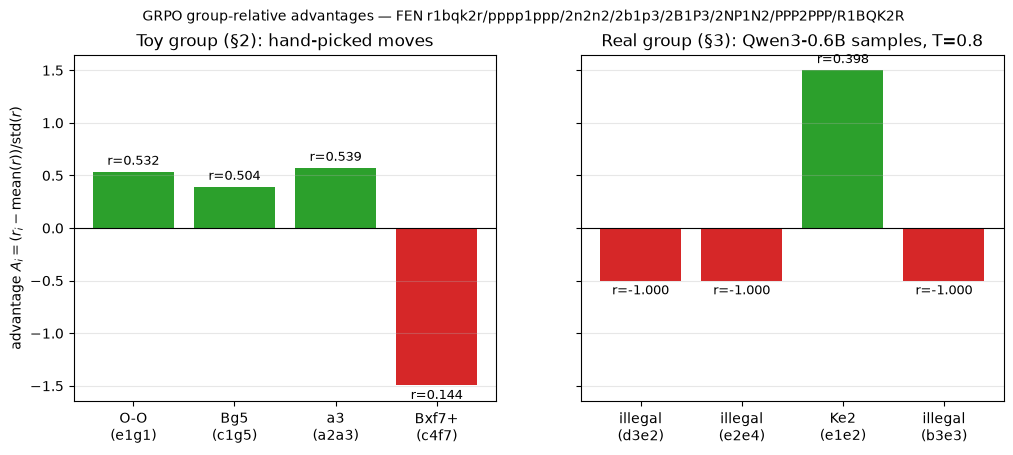

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, scored, rew, adv, title in [
    (axes[0], toy_scored, toy_rewards, toy_adv, "Toy group (§2): hand-picked moves"),
    (axes[1], real_scored, real_rewards, real_adv, f"Real group (§3): Qwen3-1.7B samples, T={TEMPERATURE}"),
]:
    labels = [f"{s['san']}\n({s['move']})" for s in scored]
    colors = ["tab:green" if a > 0 else ("tab:red" if a < 0 else "tab:gray") for a in adv.tolist()]
    bars = ax.bar(range(len(labels)), adv.numpy(), color=colors)
    for b, r_ in zip(bars, rew.tolist()):
        y = b.get_height()
        ax.annotate(f"r={r_:.3f}", (b.get_x() + b.get_width() / 2, y), ha="center",
                    va="bottom" if y >= 0 else "top", fontsize=9, xytext=(0, 3 if y >= 0 else -3),
                    textcoords="offset points")
    ax.set_xticks(range(len(labels)), labels)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
axes[0].set_ylabel(r"advantage $A_i = (r_i - \mathrm{mean}(r)) / \mathrm{std}(r)$")
fig.suptitle(f"GRPO group-relative advantages — FEN {FEN.split(' ')[0]}", fontsize=10)
plt.savefig(FIG_DIR / "grpo_advantages.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. On-policy distillation

From the OPD notes, OPD minimises the sequence-level **reverse KL** over **student-generated** trajectories:

$$\mathcal{L}_{\text{OPD}}(\theta) = \mathbb{E}_{x \sim \mathcal{D}_x, \hat{y} \sim \pi_\theta} \left[ \sum_{t=1}^{T} D_{\text{KL}}(p_t \| q_t) \right]$$

where $p_t$ = student next-token distribution and $q_t$ = teacher next-token distribution, **both evaluated on
the student's own prefix** $\hat{y}_{<t}$.

Two of the three variants are computed here (the third, top-k, restricts the KL to the student's top-k tokens):

| Variant | Per-position quantity |
|---|---|
| **Sampled-token** (cheapest; unbiased Monte-Carlo estimator) | $\ell_t = \log p_t(\hat{y}_t) - \log q_t(\hat{y}_t)$ |
| **Full-vocabulary** (densest, $O(BTM)$) | $D_{\text{KL}}(p_t \| q_t) = \sum_v p_t(v)\,[\log p_t(v) - \log q_t(v)]$ |

### The teacher — a CPU substitution (read this)

A real OPD run uses a **stronger teacher** (e.g. a larger Qwen3 or a thinking model). To stay CPU-feasible
**the teacher here is the same Qwen3-1.7B weights given privileged information**: its prompt additionally
contains Stockfish's best move and evaluation. It scores the **same student tokens** $\hat{y}$ with teacher
forcing. So $q_t$ = "what would the model predict next if it knew the engine's answer", and the per-token KL
shows *where the student's own trace departs from an engine-informed version of itself*.
This is context distillation, not a stronger-teacher result — the numbers illustrate the **mechanics**, not
the gains you'd get from a real teacher. (Per the notes, same-family teachers trained on the same data are
often "distributionally indistinguishable" — the privileged hint is what gives this teacher something new.)

The student samples at $T = 1$ with no top-k/top-p, so $\hat{y}_t \sim p_t$ exactly and $\ell_t$ is the unbiased
estimator the notes describe.

In [17]:
STUDENT_TEMPERATURE = 1.0
OPD_MAX_NEW_TOKENS = 64

question = (f"Chess position (FEN): {FEN}\nWhite to move. In one short sentence give the key idea, "
            "then give the best move in UCI notation.")
hint = (f"\n\n[Privileged hint from a strong engine: the best move is {BEST_SAN} ({BEST_UCI}), "
        f"evaluation {ROOT_CP:+d} centipawns for White.]")


def chat_prompt(user_text):
    return tokenizer.apply_chat_template([{"role": "user", "content": user_text}], tokenize=False,
                                         add_generation_prompt=True, enable_thinking=False)


student_ids = tokenizer(chat_prompt(question), return_tensors="pt").input_ids
teacher_ids = tokenizer(chat_prompt(question + hint), return_tensors="pt").input_ids
Ps, Pt = student_ids.shape[1], teacher_ids.shape[1]

torch.manual_seed(SEED)
with torch.no_grad():
    s_out = model.generate(student_ids, attention_mask=torch.ones_like(student_ids), do_sample=True,
                           temperature=STUDENT_TEMPERATURE, top_k=0, top_p=1.0,
                           max_new_tokens=OPD_MAX_NEW_TOKENS, pad_token_id=tokenizer.pad_token_id)
y_hat = s_out[0, Ps:]
eos_pos = [k for k, tid in enumerate(y_hat.tolist()) if tid in EOS_IDS]
y_hat = y_hat[: eos_pos[0] + 1] if eos_pos else y_hat
T_opd = y_hat.shape[0]
trace_tokens = [tokenizer.decode([tid]) for tid in y_hat.tolist()]
print(f"student prompt: {Ps} tokens | teacher prompt: {Pt} tokens (adds the hint) | trace: {T_opd} tokens")
print("student trace ŷ:", repr(tokenizer.decode(y_hat, skip_special_tokens=True)))

student prompt: 99 tokens | teacher prompt: 131 tokens (adds the hint) | trace: 64 tokens
student trace ŷ: "Key idea: The position is in a half-open corner, with White to move, and Black has 5 pawns on their side of the board. White should play pawns to block Black's potential to control the bottom-left of the board.\n\nBest move in UCI notation:  \n**p1 b3**"


### 4.1 Teacher scores the same tokens

Two teacher-forced forward passes over **the same** $\hat{y}$:
student context = student prompt + $\hat{y}_{<t}$ → $p_t$; teacher context = teacher prompt + $\hat{y}_{<t}$ → $q_t$.
We keep the full next-token distributions (vocab ≈ 151k) at every position so we can compute the
full-vocabulary KL, plus the notes' monitoring metrics:

- **Overlap ratio** $\mathbb{E}_t\big[\frac{|S_t^{(p)} \cap S_t^{(q)}|}{k}\big]$ with $S_t$ = top-$k$ token sets ($k = 10$)
- **Entropy gap** $\Delta H_t = |H(q_t) - H(p_t)|$

For contrast we also print the **forward** KL $D_{\text{KL}}(q_t \| p_t)$ — what off-policy KD on teacher samples
would minimise. OPD's objective is the reverse one, $D_{\text{KL}}(p_t \| q_t)$.

In [18]:
TOP_K = 10

with torch.no_grad():
    s_seq = torch.cat([student_ids[0], y_hat])[None]
    t_seq = torch.cat([teacher_ids[0], y_hat])[None]
    log_p = F.log_softmax(model(s_seq).logits[0, Ps - 1:Ps - 1 + T_opd].double(), dim=-1)   # (T, V) student
    log_q = F.log_softmax(model(t_seq).logits[0, Pt - 1:Pt - 1 + T_opd].double(), dim=-1)   # (T, V) teacher

p, q = log_p.exp(), log_q.exp()
logp_tok = log_p.gather(-1, y_hat[:, None]).squeeze(-1)
logq_tok = log_q.gather(-1, y_hat[:, None]).squeeze(-1)
ell = logp_tok - logq_tok                       # sampled-token variant
kl_rev = (p * (log_p - log_q)).sum(-1)          # D_KL(p_t || q_t)  -- OPD objective
kl_fwd = (q * (log_q - log_p)).sum(-1)          # D_KL(q_t || p_t)  -- contrast only
H_p, H_q = -(p * log_p).sum(-1), -(q * log_q).sum(-1)
entropy_gap = (H_q - H_p).abs()
topk_p, topk_q = log_p.topk(TOP_K, dim=-1).indices, log_q.topk(TOP_K, dim=-1).indices
overlap = torch.tensor([len(set(topk_p[t].tolist()) & set(topk_q[t].tolist())) / TOP_K for t in range(T_opd)])

assert (kl_rev >= -1e-9).all() and (kl_fwd >= -1e-9).all(), "KL must be non-negative"
opd_df = pd.DataFrame({
    "t": range(T_opd), "token": [repr(s) for s in trace_tokens],
    "log p_t(ŷ_t)": logp_tok.tolist(), "log q_t(ŷ_t)": logq_tok.tolist(),
    "ell_t": ell.tolist(), "KL(p||q)": kl_rev.tolist(), "KL(q||p)": kl_fwd.tolist(),
    "overlap@10": overlap.tolist(), "entropy_gap": entropy_gap.tolist(),
})
print(opd_df.round(4).to_string(index=False))
print(f"\nsequence OPD loss  Σ_t KL(p_t||q_t) = {kl_rev.sum():.4f}   |  sampled-token estimate Σ_t ell_t = {ell.sum():.4f}")
print(f"mean overlap ratio @k={TOP_K}: {overlap.mean():.3f}   |   mean entropy gap: {entropy_gap.mean():.4f} nats")

 t        token  log p_t(ŷ_t)  log q_t(ŷ_t)   ell_t  KL(p||q)  KL(q||p)  overlap@10  entropy_gap
 0        'Key'       -1.4726       -1.3404 -0.1322    0.0052    0.0051         0.9       0.0171
 1      ' idea'       -0.0254       -0.0243 -0.0012    0.0001    0.0001         1.0       0.0039
 2          ':'       -0.0000       -0.0001  0.0000    0.0000    0.0000         0.9       0.0000
 3       ' The'       -0.7820       -0.7014 -0.0806    0.0131    0.0136         1.0       0.0314
 4  ' position'       -0.2339       -0.8509  0.6170    0.4586    2.4180         0.6       1.0047
 5        ' is'       -0.1562       -0.1290 -0.0272    0.0374    0.0372         0.8       0.0350
 6        ' in'       -1.2839       -0.7329 -0.5510    0.3154    0.3187         0.7       0.7323
 7         ' a'       -0.3471       -0.2547 -0.0924    0.0371    0.0308         0.8       0.1546
 8      ' half'       -6.2982       -6.4082  0.1100    0.2075    0.2244         0.7       0.0256
 9      '-open'       -0.9597 

### 4.2 Figure — where does the student diverge from the teacher?

Top: per-token sampled-token $\ell_t$ and full-vocabulary $D_{\text{KL}}(p_t\|q_t)$ over the student's trace.
Bottom: the same full-vocab KL as a heatmap strip. Every token gets its own signal — compare that with
GRPO's single advantage per completion. $\ell_t$ can be negative on individual tokens (it is a single-sample
estimate); its expectation under $\hat{y}_t \sim p_t$ is the non-negative full KL.

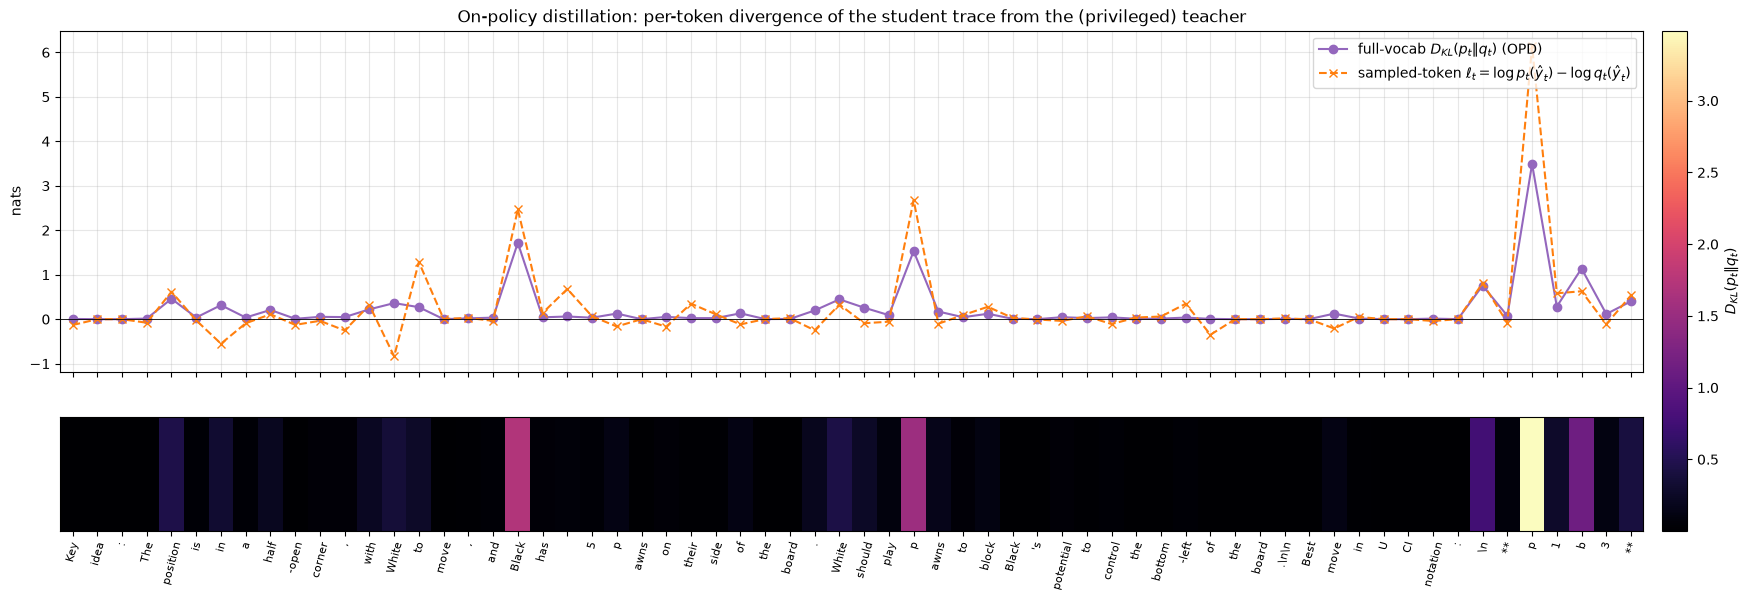

In [19]:
xs = np.arange(T_opd)
labels = [s.replace("\n", "\\n") for s in trace_tokens]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(max(10, T_opd * 0.38), 6.5), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(xs, kl_rev.numpy(), marker="o", color="tab:purple", label=r"full-vocab $D_{KL}(p_t \| q_t)$ (OPD)")
ax1.plot(xs, ell.numpy(), marker="x", ls="--", color="tab:orange",
         label=r"sampled-token $\ell_t = \log p_t(\hat y_t) - \log q_t(\hat y_t)$")
ax1.axhline(0, color="black", lw=0.6)
ax1.set_ylabel("nats")
ax1.set_title("On-policy distillation: per-token divergence of the student trace from the (privileged) teacher")
ax1.legend(loc="upper right")
ax1.grid(True, alpha=0.3)
im = ax2.imshow(kl_rev.numpy()[None, :], aspect="auto", cmap="magma")
ax2.set_yticks([])
ax2.set_xticks(xs, labels, rotation=75, fontsize=8)
fig.colorbar(im, ax=[ax1, ax2], pad=0.01, label=r"$D_{KL}(p_t \| q_t)$")
plt.savefig(FIG_DIR / "opd_per_token_kl.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Side-by-side: density of the three training signals

Same position, three signals, all computed from real forward passes above:

- **SFT** — one fixed target: Stockfish's best move appended to the §3 prompt. Signal per target token:
  cross-entropy $-\log\pi_\theta(y^*_t)$. Dense, but on tokens the student did *not* choose (off-policy).
- **GRPO** — the §3 group: one scalar advantage $A_i$ per completion, **broadcast** to all its tokens.
- **OPD** — the §4 trace: one value per token, $-\ell_t$ (positive = the teacher likes this token more than
  the student did); the full-vocab variant gives a whole distribution per token.

In [20]:
sft_target = " " + BEST_UCI
sft_ids = tokenizer(grpo_prompt + sft_target, return_tensors="pt").input_ids
assert torch.equal(sft_ids[0, :P], enc.input_ids[0]), "prompt tokenisation must be a prefix"
n_sft = sft_ids.shape[1] - P
with torch.no_grad():
    sft_ce = -completion_logprobs(model(sft_ids).logits, sft_ids, P)[0]
sft_tokens = [tokenizer.decode([t]) for t in sft_ids[0, P:].tolist()]

grpo_signal = (real_adv[:, None] * real_mask).numpy()
n_grpo_tokens = int(real_mask.sum().item())
V = log_q.shape[-1]

summary = pd.DataFrame([
    {"method": "SFT", "tokens sampled by": "teacher/dataset (off-policy)", "supervised tokens": n_sft,
     "distinct scalar signals": n_sft, "signals per token": 1.0, "signal": "CE on fixed target"},
    {"method": "GRPO", "tokens sampled by": "student (on-policy)", "supervised tokens": n_grpo_tokens,
     "distinct scalar signals": G, "signals per token": G / n_grpo_tokens, "signal": "1 advantage / sequence"},
    {"method": "OPD (sampled-token)", "tokens sampled by": "student (on-policy)", "supervised tokens": T_opd,
     "distinct scalar signals": T_opd, "signals per token": 1.0, "signal": "ell_t per token"},
    {"method": "OPD (full-vocab)", "tokens sampled by": "student (on-policy)", "supervised tokens": T_opd,
     "distinct scalar signals": T_opd * V, "signals per token": float(V), "signal": "teacher distribution q_t"},
])
print(f"SFT target {sft_target!r} -> tokens {sft_tokens}, CE per token {sft_ce.numpy().round(4).tolist()}")
print(summary.round(3).to_string(index=False))

SFT target ' c1g5' -> tokens [' c', '1', 'g', '5'], CE per token [1.8417, 1.0282, 3.5206, 0.0702]
             method            tokens sampled by  supervised tokens  distinct scalar signals  signals per token                   signal
                SFT teacher/dataset (off-policy)                  4                        4              1.000       CE on fixed target
               GRPO          student (on-policy)                 24                        4              0.167   1 advantage / sequence
OPD (sampled-token)          student (on-policy)                 64                       64              1.000          ell_t per token
   OPD (full-vocab)          student (on-policy)                 64                  9723904         151936.000 teacher distribution q_t


### 5.1 Figure — one row per method

Each cell is one supervised token; colour is the per-token training signal. GRPO's rows are constant
(one number smeared across every token of a completion), while SFT and OPD vary token by token —
but only OPD does so **on the student's own tokens**.

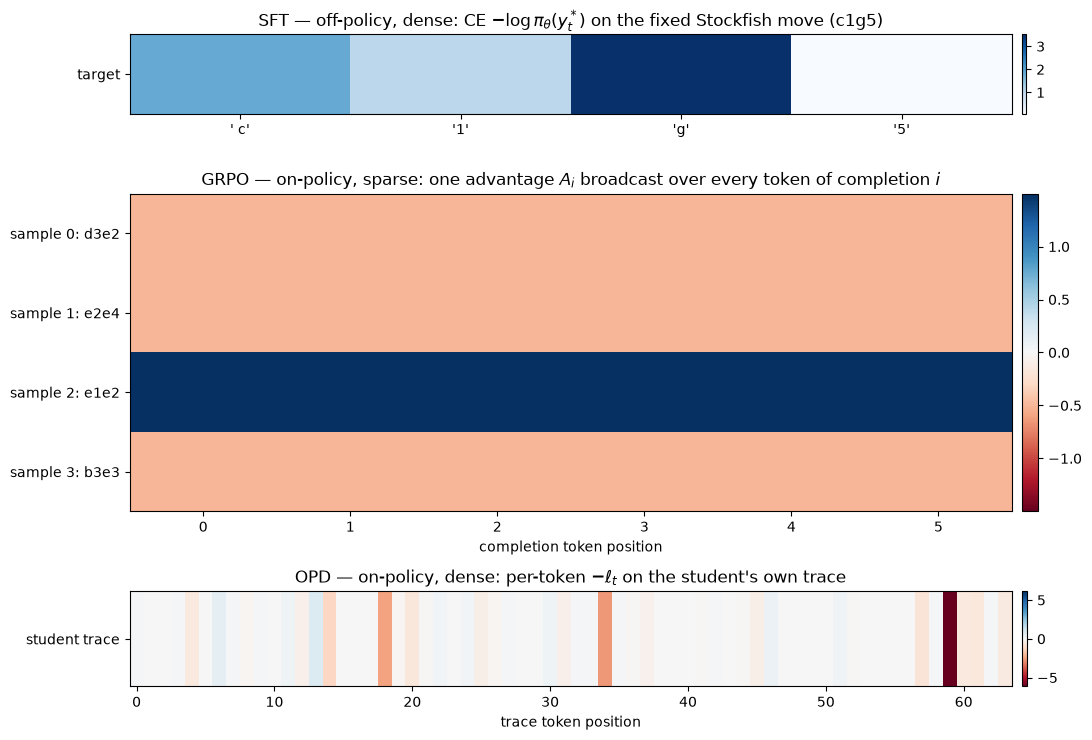

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), gridspec_kw={"height_ratios": [1, G, 1.2]})

ax = axes[0]
im0 = ax.imshow(sft_ce.numpy()[None, :], aspect="auto", cmap="Blues")
ax.set_xticks(range(n_sft), [repr(s) for s in sft_tokens])
ax.set_yticks([0], ["target"])
ax.set_title(r"SFT — off-policy, dense: CE $-\log\pi_\theta(y^*_t)$ on the fixed Stockfish move " + f"({BEST_UCI})")
fig.colorbar(im0, ax=ax, pad=0.01)

ax = axes[1]
vmax = max(1e-6, float(np.abs(grpo_signal).max()))
grpo_plot = np.where(real_mask.numpy() > 0, grpo_signal, np.nan)
im1 = ax.imshow(grpo_plot, aspect="auto", cmap="RdBu", vmin=-vmax, vmax=vmax)
ax.set_yticks(range(G), [f"sample {g}: {parsed[g] or '<none>'}" for g in range(G)])
ax.set_xlabel("completion token position")
ax.set_title(r"GRPO — on-policy, sparse: one advantage $A_i$ broadcast over every token of completion $i$")
fig.colorbar(im1, ax=ax, pad=0.01)

ax = axes[2]
neg_ell = (-ell).numpy()
vmax = max(1e-6, float(np.abs(neg_ell).max()))
im2 = ax.imshow(neg_ell[None, :], aspect="auto", cmap="RdBu", vmin=-vmax, vmax=vmax)
ax.set_yticks([0], ["student trace"])
ax.set_xlabel("trace token position")
ax.set_title(r"OPD — on-policy, dense: per-token $-\ell_t$ on the student's own trace")
fig.colorbar(im2, ax=ax, pad=0.01)

plt.tight_layout()
plt.savefig(FIG_DIR / "signal_density.png", dpi=150, bbox_inches="tight")
plt.show()

Release the Stockfish process and list the figures this run wrote.

In [22]:
engine.quit()
print("figures written:", sorted(p.name for p in FIG_DIR.glob("*.png")))

figures written: ['game_eval_curve.png', 'grpo_advantages.png', 'kl_penalty_curve.png', 'opd_per_token_kl.png', 'signal_density.png']


## 6. Demonstration — a full game with the trained policy

Everything above dissects *one position*. A chess game is a **sequence of 30–60 such
decisions**, and that is where chess gets hard for an LLM — not tactically, but
strategically:

- **Branching.** ~30–40 legal moves per ply; Shannon's famous estimate is $10^{120}$
  plausible games. No model "searches" this — it must *judge* a position in one
  forward pass.
- **The horizon problem.** A pawn sacrifice for long-term initiative looks like −2 pawns
  to a shallow evaluator for twenty moves before it pays off. Strategy is exactly the
  part whose value *materialises later than it is created*.
- **No token-level signature.** Tactics (fork, pin, back-rank mate) are locally
  computable from the piece configuration; strategy (pawn structure, king safety, piece
  activity, space) is a *global property with no single-token correlate*. A language
  model sees a FEN string — it has no spatial ground truth to lean on.

| | tactical | strategic |
|---|---|---|
| time scale | 1–5 plies | 20–60 plies |
| recognisable by | concrete patterns | position *character* |
| eval trajectory | jumps sharply | drifts slowly |
| for an LLM | learnable from move text | almost invisible in text |
| RL credit assignment | easy (local cause/effect) | brutal (1 reward, 30+ causes) |

This last row is why the RL pipeline in this repo is hard: **one scalar reward at the end
of the game must assign credit to every one of ~30 decisions** — the strategic ones,
whose quality is only revealed by the *whole* game that follows them.

Below we load the policy the repo actually trained — a **Qwen3-1.7B** model fine-tuned
with SFT + GRPO (`checkpoints/rl/final`, temperature 0.1, matching
`evaluation_results/benchmark_results.json`) — and let it play a game. If the trained
weights are not on this machine (they live on the training box), the cell falls back to
the *base* Qwen3-1.7B so the full game pipeline still runs and demonstrates exactly what
training has to fix.

In [23]:
import gc
import time
from pathlib import Path

RL_CKPT = Path("checkpoints/rl/final")
trained_available = (RL_CKPT / "adapter_config.json").exists() or (RL_CKPT / "config.json").exists()

# Free the §0 model first — two policy models do not fit in a laptop's RAM.
del model
gc.collect()


def quantize_linears_int8_inplace(module):
    """Dynamic int8 quantization of every nn.Linear, in place.

    torch.ao.quantization.quantize_dynamic deep-copies the whole model, which
    OOMs a 16 GB laptop on a 1.7B checkpoint; per-module conversion never
    holds more than one float layer plus its int8 copy.
    """
    import torch.nn.quantized.dynamic as nnqd

    for name, child in module.named_children():
        if isinstance(child, torch.nn.Linear):
            cf = child.float()
            cf.qconfig = torch.ao.quantization.default_dynamic_qconfig
            setattr(module, name, nnqd.Linear.from_float(cf))
        else:
            quantize_linears_int8_inplace(child)


GAME_MODEL_ID = "Qwen/Qwen3-1.7B"
game_model = game_tokenizer = None
game_model_source = None
try:
    if trained_available:
        from qwen_chess_rl.evaluation.benchmark import load_model_for_eval

        game_model, game_tokenizer = load_model_for_eval(str(RL_CKPT))
        game_model_source = f"trained RL checkpoint ({RL_CKPT})"
    else:
        print("[DAT-342] trained RL weights not found locally — using base model fallback")
except Exception as exc:  # network / OOM / missing files: degrade, don't kill the run
    print(f"[DAT-342] loading {game_model_source or RL_CKPT} failed ({exc!r}); falling back to base")

if game_model is None:
    game_tokenizer = AutoTokenizer.from_pretrained(GAME_MODEL_ID)
    game_model = AutoModelForCausalLM.from_pretrained(
        GAME_MODEL_ID, dtype=torch.bfloat16, low_cpu_mem_usage=True
    ).eval()
    quantize_linears_int8_inplace(game_model)
    # quantized Linears compute in fp32 — cast the modules that stayed bf16
    for mod in game_model.modules():
        if isinstance(mod, torch.nn.Embedding) or "Norm" in type(mod).__name__:
            mod.float()
    game_model_source = (f"BASE {GAME_MODEL_ID} (int8 dynamic quant, CPU) — "
                         "no trained RL weights on this machine")

print("game policy:", game_model_source)

[DAT-342] trained RL weights not found locally — using base model fallback



Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]


Loading weights:  47%|████▋     | 147/311 [00:00<00:00, 1467.93it/s]


Loading weights: 100%|██████████| 311/311 [00:00<00:00, 1637.66it/s]

/home/ibrahim/workspace/qwen-chess-rl/.venv/lib/python3.11/site-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  qweight = torch.quantize_per_tensor(


game policy: BASE Qwen/Qwen3-1.7B (int8 dynamic quant, CPU) — no trained RL weights on this machine


### 6.1 How a move is chosen

We follow the repo's shared inference helper `choose_uci_move`
(`qwen_chess_rl/inference.py`), which is what the benchmark suite uses:

1. **Free-generate** a few sampled completions with `temperature = 0.1` (the same
   temperature as `evaluation_results/benchmark_results.json`). The first completion that
   parses to a legal UCI move is played — cheap, and the path a *trained* policy almost
   always takes, because SFT/RL teaches it the `e2e4`-style output format.
2. **Fallback:** rank *every* legal move by teacher-forced log-probability and take the
   best. Robust but expensive: the repo helper runs one forward pass per legal move, so
   on CPU we batch all candidates into **one padded forward pass** (right-padded with an
   attention mask — causality means the padding never leaks into the scored positions).
   Same numbers, ~30× fewer forward passes. A base (untrained) model lives in this
   fallback — which is itself the demonstration: it knows legal *form* only after
   scoring, not in its generations.

The base 1.7B model here is int8-dynamically-quantized for CPU speed; the trained
checkpoint on the training box runs bf16 as usual (`load_model_for_eval`).

In [24]:
import chess.pgn
import time

from qwen_chess_rl.data.dataset import format_fen_prompt


@torch.no_grad()
def score_legal_moves(model, tokenizer, board, temperature=0.1, n_samples=4):
    """Repo `choose_uci_move` strategy, batched for CPU. Returns (uci, path)."""
    legal = [m.uci() for m in board.legal_moves]
    prompt = format_fen_prompt(board.fen())
    inputs = tokenizer(prompt, return_tensors="pt")

    # stage 1 — sampled free generation
    gen_kwargs = dict(max_new_tokens=5, do_sample=temperature > 0,
                      pad_token_id=tokenizer.pad_token_id,
                      eos_token_id=tokenizer.eos_token_id,
                      num_return_sequences=n_samples)
    if temperature > 0:
        gen_kwargs["temperature"] = temperature
    out = model.generate(**inputs, **gen_kwargs)
    for row in out:
        cand = tokenizer.decode(row[inputs["input_ids"].shape[1]:],
                                skip_special_tokens=True).strip()
        for marker in ("</think>", "assistant", "\n"):
            cand = cand.split(marker)[-1].strip()
        parts = cand.split()
        if parts:
            try:
                mv = chess.Move.from_uci(parts[0])
                if mv in board.legal_moves:
                    return mv.uci(), "generation"
            except ValueError:
                continue

    # stage 2 — ALL legal moves ranked by log-prob in ONE padded forward pass
    p_ids = inputs["input_ids"][0]
    cand_ids = [tokenizer(" " + u, add_special_tokens=False)["input_ids"] for u in legal]
    maxlen = max(len(p_ids) + len(c) for c in cand_ids)
    pad = tokenizer.pad_token_id
    batch = torch.full((len(cand_ids), maxlen), pad, dtype=torch.long)
    attn = torch.zeros((len(cand_ids), maxlen), dtype=torch.long)
    for i, c in enumerate(cand_ids):
        batch[i, :len(p_ids) + len(c)] = torch.cat([p_ids, torch.tensor(c)])
        attn[i, :len(p_ids) + len(c)] = 1
    logits = model(input_ids=batch, attention_mask=attn).logits
    best, best_score, lp_all = None, float("-inf"), []
    for i, c in enumerate(cand_ids):
        lp = sum(logits[i, len(p_ids) + j - 1].log_softmax(-1)[t].item()
                 for j, t in enumerate(c))
        lp_all.append(lp)
        if lp > best_score:
            best, best_score = legal[i], lp
    return best, "logprob"


MAX_PLIES = 30            # hard cap — the demo needs a game, not a marathon
GAME_TIME_BUDGET_S = 600  # wall-clock guard for CPU runs


def play_game(max_plies=MAX_PLIES, model_plays_white=True, temperature=0.1,
              skill_level=1, move_time=0.1, time_budget_s=GAME_TIME_BUDGET_S):
    """Play one game: policy model vs limited-strength Stockfish.

    Returns (board, record, pgn_text, reason, path_counts). `record` rows are
    (ply, mover, san, eval_cp_after_move_from_white_pov, model_move_seconds).
    """
    board = chess.Board()
    opponent = chess.engine.SimpleEngine.popen_uci(STOCKFISH_PATH)
    opponent.configure({"Skill Level": skill_level, "Threads": 1})
    play_limit = chess.engine.Limit(time=move_time)
    eval_limit = chess.engine.Limit(time=0.05)

    record, reason = [], "max plies"
    paths = {"generation": 0, "logprob": 0}
    pgn_game = chess.pgn.Game()
    pgn_game.headers["White"] = "Qwen3-1.7B (policy)"
    pgn_game.headers["Black"] = f"Stockfish 17.1 (skill {skill_level})"
    node = pgn_game

    t0 = time.time()
    while not board.is_game_over(claim_draw=False) and len(record) < max_plies:
        if time.time() - t0 > time_budget_s:
            reason = "time budget"
            break
        model_turn = (board.turn == chess.WHITE) == model_plays_white
        if model_turn:
            m_start = time.time()
            uci, path = score_legal_moves(game_model, game_tokenizer, board,
                                          temperature=temperature)
            paths[path] += 1
            m_seconds = time.time() - m_start
        else:
            uci = opponent.play(board, play_limit).move.uci()
            m_seconds = float("nan")

        move = chess.Move.from_uci(uci)
        san = board.san(move)
        board.push(move)
        node = node.add_variation(move)
        info = opponent.analyse(board, eval_limit)
        eval_cp = info["score"].white().score(mate_score=10_000)
        record.append((len(record) + 1, "model" if model_turn else "stockfish",
                       san, eval_cp, m_seconds))

    if board.is_game_over(claim_draw=False):
        outcome = board.outcome(claim_draw=False)
        reason = f"{outcome.termination.name} ({outcome.result()})"
    pgn_game.headers["Result"] = board.result(claim_draw=False)
    pgn_game.headers["Termination"] = reason
    opponent.quit()
    return board, record, str(pgn_game), reason, paths


game_board, game_record, game_pgn, game_reason, game_paths = play_game()

print(f"reason: {game_reason}  |  plies: {len(game_record)}  |  "
      f"model decisions: {game_paths['generation']} via generation, "
      f"{game_paths['logprob']} via logprob ranking")
for ply, mover, san, eval_cp, m_s in game_record:
    who = "model     " if mover == "model" else "stockfish "
    ms = f"{m_s:6.2f}s" if m_s == m_s else "     --"
    print(f"{ply:3d} {who} {san:8s} eval(W)={eval_cp:+6d}  model time {ms}")
print()
print("PGN:")
print(game_pgn)
print()
print(game_board)

reason: max plies  |  plies: 30  |  model decisions: 0 via generation, 15 via logprob ranking
  1 model      g4       eval(W)=  -148  model time  15.51s
  2 stockfish  d5       eval(W)=   -94  model time      --
  3 model      Na3      eval(W)=  -196  model time  19.12s
  4 stockfish  Nc6      eval(W)=  -192  model time      --
  5 model      e3       eval(W)=  -233  model time  19.37s
  6 stockfish  h6       eval(W)=  -156  model time      --
  7 model      c4       eval(W)=  -218  model time  27.48s
  8 stockfish  Nf6      eval(W)=  -202  model time      --
  9 model      Bg2      eval(W)=  -269  model time  28.85s
 10 stockfish  a6       eval(W)=  -137  model time      --
 11 model      Nb1      eval(W)=  -272  model time  30.82s
 12 stockfish  d4       eval(W)=  -137  model time      --
 13 model      e4       eval(W)=  -365  model time  30.92s
 14 stockfish  Nxg4     eval(W)=  -315  model time      --
 15 model      b3       eval(W)=  -354  model time  28.09s
 16 stockfish  g5    

### 6.2 Figure — the evaluation seesaw

The eval column above is Stockfish's score after every ply, from White's point of view.
Plotting it turns the game into the talk's central visual: strategic pressure shows up as
a slow *drift*, tactical shots as sharp *spikes* — and the model's job during training is
to predict, 30 plies ahead, which side of zero the curve ends on.

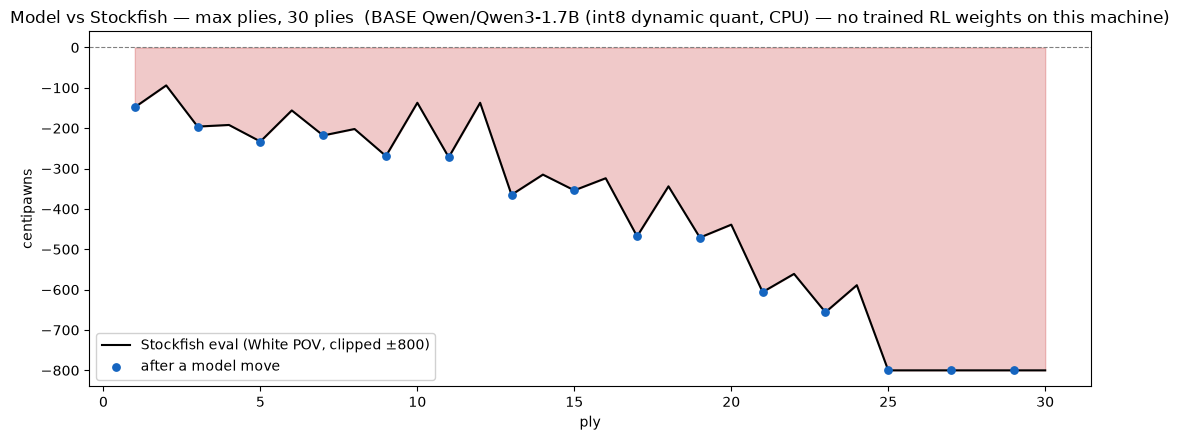

In [25]:
fig, ax = plt.subplots(figsize=(11, 4.5))
plies = [r[0] for r in game_record]
evals = [max(-800, min(800, r[3])) for r in game_record]
model_plies = [p for p, r in zip(plies, game_record) if r[1] == "model"]
model_evals = [e for r, e in zip(game_record, evals) if r[1] == "model"]

ax.axhline(0, color="grey", lw=0.8, ls="--")
ax.fill_between(plies, evals, 0, where=[e >= 0 for e in evals],
                color="#2e7d32", alpha=0.25, interpolate=True)
ax.fill_between(plies, evals, 0, where=[e < 0 for e in evals],
                color="#c62828", alpha=0.25, interpolate=True)
ax.plot(plies, evals, color="black", lw=1.5, label="Stockfish eval (White POV, clipped ±800)")
ax.scatter(model_plies, model_evals, s=28, color="#1565c0", zorder=3,
           label="after a model move")
ax.set_xlabel("ply")
ax.set_ylabel("centipawns")
ax.set_title(f"Model vs Stockfish — {game_reason}, {len(game_record)} plies  ({game_model_source})")
ax.legend(loc="lower left", framealpha=0.9)
fig.tight_layout()
fig.savefig(FIG_DIR / "game_eval_curve.png", dpi=150)
plt.show()

### 6.3 Sanity metric — legal-move rate

The one number worth putting on a slide from this section. On a fixed set of eight
positions (the §0 FEN plus seven standard ones, from the empty board to a sharp Sicilian)
we ask the policy for a move and count how often it is *legal*. An untrained model
halting this pipeline with garbage output is the "before" picture;
`evaluation_results/benchmark_results.json` records `legal_move_pct = 1.0` over 1 000
positions for the trained checkpoint — the "after".

In [26]:
SANITY_FENS = [
    FEN,                                                                # the §0 position
    "rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQKBNR w KQkq - 0 1",         # start
    "rnbqkbnr/ppp2ppp/3p4/4p3/4P3/5N2/PPPP1PPP/RNBQKB1R w KQkq - 0 3",  # open game
    "8/2p5/3p4/KP5r/1R3p1k/8/4P1P1/8 w - - 0 1",                        # Ropša endgame study
    "4k3/8/8/8/8/8/4R3/4K3 w - - 0 1",                                  # KRK technique
    "r4rk1/1pp1qppp/p1np1n2/2b1p1B1/2B1P1b1/P1NP1N2/1PP1QPPP/R4RK1 w - - 0 10",  # Italian
    "2rr3k/pp3pp1/1nnqbN1p/3pN3/2pP4/2P3Q1/PPB4P/R4RK1 w - - 0 1",      # sharp middlegame
    "8/P7/8/8/8/8/2p5/k1K5 w - - 0 1",                                  # promotion race
]

legal = tried = 0
sanity_t0 = time.time()
for fen in SANITY_FENS:
    if time.time() - sanity_t0 > 420:
        print("(stopped early — CPU time budget)")
        break
    board_i = chess.Board(fen)
    uci, path = score_legal_moves(game_model, game_tokenizer, board_i, temperature=0.1)
    ok = uci is not None and chess.Move.from_uci(uci) in board_i.legal_moves
    legal += int(ok)
    tried += 1
    print(f"{'legal ' if ok else 'ILLEGAL'} ({path:10s}) {fen.split()[0][:36]:38s} -> {uci}")
print(f"\nlegal-move rate: {legal}/{tried} = {legal / tried:.0%}")

legal  (logprob   ) r1bqk2r/pppp1ppp/2n2n2/2b1p3/2B1P3/2   -> a1b1


legal  (logprob   ) rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/R   -> g2g4


legal  (logprob   ) rnbqkbnr/ppp2ppp/3p4/4p3/4P3/5N2/PPP   -> b1c3


legal  (logprob   ) 8/2p5/3p4/KP5r/1R3p1k/8/4P1P1/8        -> e2e4


legal  (logprob   ) 4k3/8/8/8/8/8/4R3/4K3                  -> e2e3


legal  (logprob   ) r4rk1/1pp1qppp/p1np1n2/2b1p1B1/2B1P1   -> g2g3


legal  (logprob   ) 2rr3k/pp3pp1/1nnqbN1p/3pN3/2pP4/2P3Q   -> c2e4


legal  (logprob   ) 8/P7/8/8/8/8/2p5/k1K5                  -> c1c2

legal-move rate: 8/8 = 100%


## 7. Why on-policy distillation helps exactly here

The game above shows the failure mode this talk keeps circling: **after one weak move the
model is in territory its training data never covered**. Off-policy SFT trains on Lichess
grandmaster positions; the base model's move 6 drags the game somewhere no grandmaster
game ever went, and from there SFT has *no gradient at all* — there is no labelled example
for the position the student actually created. This is exposure bias, and in chess it
compounds: one drifting move changes the whole character of the game, i.e. the *strategic*
part — precisely what the §6 table said is hardest to learn from text.

On-policy distillation attacks it directly, and the section above is already the worked
example:

- **Corrections in the states the student visits.** §4 sampled the *student's own*
  completion and had the teacher score those exact tokens. Scale that from one completion
  to whole self-play games and every weak move in the §6 record becomes a training
  signal — the teacher grades the student's game, not a grandmaster's.
- **Dense signal for a long-horizon problem.** GRPO (§2–§3) gives one scalar reward for a
  ~30-ply episode; the §5.1 figure made the contrast visible — the teacher's per-token
  log-probs supervise *every* generated token. For a game whose difficulty is exactly
  "one reward, thirty causes" (§6), that density is not a luxury, it is the only
  affordable gradient.
- **LUFFY-style mixing.** You do not have to choose between the two: LUFFY mixes
  off-policy expert moves into on-policy GRPO, so the sparse strategic signal from wins
  and the dense distillation signal coexist. This repo's planned M4 ablation — LUFFY
  on/off on **Qwen3-1.7B** (`docs/rewards.md`) — tests precisely whether that mixture
  beats GRPO-only on the horizon problem.

One sentence for the slide: *SFT teaches the student to imitate good games; on-policy
distillation teaches it to recognise how its own games go wrong.*

## 8. Takeaways (slide mapping)

- **GRPO = "which of my own attempts was better?"** The group-relative advantage
  $A_i = (r_i - \operatorname{mean}(r))/\operatorname{std}(r)$ needs no critic, sums to zero within a group, and is
  exactly 0 when every sample scores the same — a group of identical (e.g. all-illegal) answers teaches nothing.
- **The ratio, clip and KL are guard-rails, not the signal.** The signal is the advantage; `ratio`/`clamp`
  bound how far one batch can push the policy (and correct sampler/trainer mismatch), and
  $e^{-\Delta} + \Delta - 1$ pulls toward $\pi_{\text{ref}}$ — often dropped ($\beta = 0$, DAPO-style) when the reward is a
  trustworthy verifier like Stockfish.
- **Aggregation is a design choice with behavioural consequences.** Sequence-mean (GRPO) down-weights tokens
  in long completions, so long wrong answers are penalised less per token; token-mean (DAPO) / constant
  normalisation (Dr. GRPO) remove that length bias.
- **Density: SFT and OPD are dense, GRPO is sparse — but only RL and OPD are on-policy.** In our example GRPO
  produced $G = 4$ numbers for the whole group, while OPD produced one per token on the student's own trace:
  OPD is "on-policy like RL, dense like SFT".
- **OPD only works if the teacher has something new *and* compatible to say.** Watch the overlap ratio and
  entropy gap before trusting it; for chess, Stockfish-as-reward (RL) and a strong chess-reasoning teacher
  (OPD) are complementary, not substitutes.
- **§6–§7: the game + why OPD** — one slide: the eval seesaw figure on the left, the SFT-vs-OPD sentence on the right.
